# Tarea 2 · Parte 2 — Evaluación, extracción estructurada y comparación de modelos

**Reglas que sigue este notebook**
1. **Misma muestra para todos los modelos:** 10 documentos y 10 clips elegidos del corpus de la Parte 1 (no se recolectó nada nuevo).
2. **Referencias hechas por personas, no por modelos:** páginas de Wikisource corregidas o validadas por voluntarios, transcripciones escritas por los autores de las fichas de Commons, transcripciones oficiales de OpenSLR 73 y, para los 2 clips de entrevistas que no tenían transcripción, **transcripción manual propia** (`datos/raw/referencias_manuales.csv`, fuera de Git porque contiene los nombres reales; en los CSV publicados la referencia ya está seudonimizada).
3. **Configuraciones fijadas antes de medir:** los 3 OCR y los 3 ASR se definieron en `herramientas.py` antes de calcular cualquier métrica y no se ajustó ningún parámetro mirando el CER/WER.
4. **Misma normalización** para referencia e hipótesis y para todos los modelos. Audio (`herramientas.normalizar`, criterio de `voz.py`): minúsculas, sin puntuación, espacios simples y sin las marcas `[HABLANTE_n]`; las tildes se conservan. Documentos (`herramientas.normalizar_doc`): lo mismo + `ſ`→`s`, sin tildes y u/v como una sola letra, porque las placas están en mayúsculas sin tildes y escriben V por U (CIRCVLO, PERV) mientras que sus transcripciones de Commons modernizan la ortografía; sin esto el CER castigaría una lectura correcta. Referencia e hipótesis pasan por la misma seudonimización antes de comparar, así que las métricas se pueden recalcular con los CSV publicados.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import herramientas as H
import voz

import json
import re
from datetime import date
from importlib.metadata import version

import jiwer
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 110)
BASE, RAW = H.BASE, H.RAW
documentos = pd.read_csv(BASE / "datos" / "documentos.csv", keep_default_na=False)
transcripciones = pd.read_csv(BASE / "datos" / "transcripciones.csv", keep_default_na=False)
refs_fuente = json.loads((RAW / "referencias_humanas.json").read_text(encoding="utf-8"))
refs_manual = pd.read_csv(RAW / "referencias_manuales.csv", keep_default_na=False)  # con nombres reales: fuera de Git
revision = json.loads((RAW / "seudonimizacion" / "revision.json").read_text(encoding="utf-8"))  # fuera de Git
seud = lambda t, i: H.seudonimizar(t, {**revision["reemplazar"], **revision.get("por_id", {}).get(i, {})})[0]
print(documentos.shape, transcripciones.shape, "| versiones:", {p: version(p) for p in ["paddleocr", "easyocr", "faster-whisper", "transformers", "jiwer"]})

(25, 17) (23, 20) | versiones: {'paddleocr': '3.7.0', 'easyocr': '1.7.2', 'faster-whisper': '1.2.1', 'transformers': '5.20.2', 'jiwer': '4.0.0'}


## 1. Muestra de evaluación (10 documentos + 10 clips del corpus original)

**Documentos** (los 3 tipos): 4 impresos (2 páginas de Palma, 1 de Garcilaso con tipografía de 1800 y 1 de la Ley de Reforma Agraria), 3 fotos de placas (una de bronce con brillo fuerte) y 3 páginas manuscritas de Guaman Poma.

**Clips** (distintas fuentes y condiciones): 7 lecturas de OpenSLR 73 (4 hablantes mujeres y 3 hombres, grabación limpia), la entrevista simulada de 2 hablantes y 2 entrevistas reales de Commons grabadas en la calle (una con ruido de estadio en el medio tiempo).

In [2]:
DOCS_EVAL = ["doc_001", "doc_003", "doc_006", "doc_008", "doc_009", "doc_010", "doc_011", "doc_020", "doc_021", "doc_022"]
CLIPS_EVAL = ["clip_006", "clip_008", "clip_009", "clip_011", "clip_013", "clip_016", "clip_018", "clip_020", "clip_021", "clip_023"]

ref_doc = {i: refs_fuente[i] for i in DOCS_EVAL}
ref_clip = {i: refs_fuente[i] for i in CLIPS_EVAL if i in refs_fuente}
for r in refs_manual.itertuples():
    if r.id in CLIPS_EVAL and r.texto_referencia.strip():
        ref_clip[r.id] = {"texto": r.texto_referencia.strip(), "procedencia": f"Transcripción manual propia ({r.transcrito_por}, {r.fecha})"}
faltan = [i for i in CLIPS_EVAL if i not in ref_clip]
assert not faltan, f"Faltan referencias manuales: {faltan}"

muestra_doc = documentos.set_index("id").loc[DOCS_EVAL, ["tipo", "descripcion"]].reset_index()
muestra_doc["procedencia_referencia"] = [ref_doc[i]["procedencia"] for i in DOCS_EVAL]
muestra_doc["texto_referencia"] = [seud(ref_doc[i]["texto"], i) for i in DOCS_EVAL]
muestra_clip = transcripciones.set_index("id").loc[CLIPS_EVAL, ["origen", "descripcion", "duracion_seg"]].reset_index()
muestra_clip["condicion"] = np.select([muestra_clip["descripcion"].str.startswith("Entrevista simulada"), muestra_clip["origen"].str.startswith("OpenSLR")],
                                      ["entrevista simulada (2 hablantes)", "lectura limpia (OpenSLR)"], "entrevista real en la calle (Commons)")
muestra_clip["procedencia_referencia"] = [ref_clip[i]["procedencia"] for i in CLIPS_EVAL]
muestra_clip["texto_referencia"] = [seud(ref_clip[i]["texto"], i) for i in CLIPS_EVAL]
print(f"Documentos: {muestra_doc['tipo'].value_counts().to_dict()} | clips: {muestra_clip['condicion'].value_counts().to_dict()} "
      f"({muestra_clip['duracion_seg'].sum() / 60:.1f} min)")
display(muestra_doc[["id", "tipo", "descripcion", "procedencia_referencia"]])
muestra_clip[["id", "condicion", "duracion_seg", "procedencia_referencia"]]

Documentos: {'impreso': 4, 'foto': 3, 'manuscrito': 3} | clips: {'lectura limpia (OpenSLR)': 7, 'entrevista real en la calle (Commons)': 2, 'entrevista simulada (2 hablantes)': 1} (11.5 min)


,id,tipo,descripcion,procedencia_referencia
0,doc_001,impreso,"Ricardo Palma, «D. Dimas de la Tijereta» (inicio)","Wikisource, página corregida por voluntarios (nivel 3)"
1,doc_003,impreso,"Ricardo Palma, «Los malditos» (inicio)","Wikisource, página validada por voluntarios (nivel 4)"
2,doc_006,impreso,"Inca Garcilaso, cap. XV «Origen de los Incas»","Wikisource, página validada por voluntarios (nivel 4)"
3,doc_008,impreso,"Decreto Ley 17716 de Reforma Agraria (1969), arts. 2-3","Wikisource, página corregida por voluntarios (nivel 3)"
4,doc_009,foto,"Placa a José Santos Chocano (1927), Lima",Transcripción humana en la descripción del archivo en Commons
5,doc_010,foto,"Placa metálica del Edificio Fénix, Lima (brillo fuerte)",Transcripción humana en la descripción del archivo en Commons
6,doc_011,foto,"Placa del ex-Círculo Militar del Perú (1937), Lima",Transcripción humana en la descripción del archivo en Commons
7,doc_020,manuscrito,"Guaman Poma (1615), la villa del Callao",Transcripción humana en la descripción del archivo en Commons
8,doc_021,manuscrito,"Guaman Poma (1615), la villa de Cañete",Transcripción humana en la descripción del archivo en Commons
9,doc_022,manuscrito,"Guaman Poma (1615), capítulo de las ciudades",Transcripción humana en la descripción del archivo en Commons


,id,condicion,duracion_seg,procedencia_referencia
0,clip_006,entrevista real en la calle (Commons),77.4,"Transcripción manual propia (Josue Alonso Soria Vasquez, 25/10/2026)"
1,clip_008,entrevista real en la calle (Commons),29.9,"Transcripción manual propia (Josue Alonso Soria Vasquez, 25/10/2026)"
2,clip_009,lectura limpia (OpenSLR),73.4,Transcripción oficial de OpenSLR 73 (line_index.tsv)
3,clip_011,lectura limpia (OpenSLR),62.4,Transcripción oficial de OpenSLR 73 (line_index.tsv)
4,clip_013,lectura limpia (OpenSLR),74.4,Transcripción oficial de OpenSLR 73 (line_index.tsv)
5,clip_016,lectura limpia (OpenSLR),51.1,Transcripción oficial de OpenSLR 73 (line_index.tsv)
6,clip_018,lectura limpia (OpenSLR),66.4,Transcripción oficial de OpenSLR 73 (line_index.tsv)
7,clip_020,lectura limpia (OpenSLR),75.0,Transcripción oficial de OpenSLR 73 (line_index.tsv)
8,clip_021,lectura limpia (OpenSLR),72.6,Transcripción oficial de OpenSLR 73 (line_index.tsv)
9,clip_023,entrevista simulada (2 hablantes),109.4,Transcripción oficial de OpenSLR 73 (line_index.tsv)


In [3]:
# texto_referencia se completa en los CSV de la Parte 1 SOLO para la muestra de evaluación
documentos["texto_referencia"] = documentos["id"].map(dict(zip(muestra_doc["id"], muestra_doc["texto_referencia"]))).fillna("")
transcripciones["texto_referencia"] = transcripciones["id"].map(dict(zip(muestra_clip["id"], muestra_clip["texto_referencia"]))).fillna("")
documentos.to_csv(BASE / "datos" / "documentos.csv", index=False)
transcripciones.to_csv(BASE / "datos" / "transcripciones.csv", index=False)
print("Referencias guardadas:", (documentos["texto_referencia"] != "").sum(), "documentos y",
      (transcripciones["texto_referencia"] != "").sum(), "clips")
muestra_doc[["id", "texto_referencia"]].assign(texto_referencia=lambda d: d["texto_referencia"].str[:150])

Referencias guardadas: 10 documentos y 10 clips


,id,texto_referencia
0,doc_001,D. DIMAS DE LA TIJERETA CUENTO DE VIEJAS QUE TRATA DE CÓMO UN ESCRIBANO LE GANÓ UN PLEITO AL DIABLO I Éras...
1,doc_003,LOS MALDITOS CRÓNICA DE LA ÉPOCA DEL NOVENO VIRREY DEL PERÚ I SAN PEDRO-MAMA Por los años de 1601 existían...
2,doc_006,"94 Historia general su vida, costumbres, dioses y sacrificios barbarísimos, fuera de todo encarecimiento. ..."
3,doc_008,"la Rural efectiva, la asistencia técnica generalizada, los mecanismos de crédito, las investigaciones agro..."
4,doc_009,La Sociedad de Bellas Artes a José Santos Chocano. Día de la Raza 1927. L. Agurto
5,doc_010,EDIFICIO FÉNIX. El Edificio Fénix fue construido en 1934 por la firma Fred T. Ley Cía. Ltd. por encargo de...
6,doc_011,Círculo Militar del Perú. Se construyó este edificio siendo Presidente de la República el general de divis...
7,doc_020,"1033 104 LA VILLA DE CALLAV, puerto de los Reys de Lima uilla CIVDAD"
8,doc_021,1037 1045 LA VILLA DE CAÑETE CIVDAD
9,doc_022,"997 1005 CAPÍTVLO PRIMERO DE LAS CIVDADES I VILLAS: CIVDAD DE NOBO REINO Santa Fe de Bocotá, ciudad tiene ..."


## 2. Modelos y configuraciones (fijados antes de medir)

| Modalidad | Clave | Modelo y configuración | Rol |
|---|---|---|---|
| OCR | `paddle_base` | PaddleOCR 3.7 (PP-OCRv6 medium: detector + reconocedor multilingüe), `lang="es"`, sin preprocesamiento | **Línea base** (también es el OCR de la Parte 1) |
| OCR | `paddle_prepro` | Igual + clasificador de orientación de página, corrección de deformación UVDoc y orientación de línea | Variante pensada para fotos |
| OCR | `easyocr` | EasyOCR 1.7 (CRAFT + CRNN), modelo `es`, CPU, orden de lectura por renglones | OCR alternativo. Se usa en lugar de Tesseract porque en Windows Tesseract exige instalar un binario con permisos de administrador; EasyOCR es otra familia de modelos (detector y reconocedor distintos) y corre con `pip` en CPU |
| ASR | `fw-small` | faster-whisper **small** (244 M parámetros), int8 en CPU, VAD on, `beam_size=5`, `language="es"` | **Línea base** |
| ASR | `fw-turbo` | faster-whisper **large-v3-turbo** (809 M), misma configuración | Modelo de la Parte 1 |
| ASR | `qwen3-asr-0.6b` | Qwen3-ASR 0.6B (Alibaba, Apache 2.0) en CPU float32, cortado por el VAD Silero de `voz.py` | ASR alternativo de otra familia |

Todos corren en la misma laptop (CPU Ryzen 7 8845HS, 8 núcleos, sin GPU), **un modelo a la vez y sin otros procesos pesados**, después de una inferencia de calentamiento fuera de la muestra. La **latencia** es el tiempo de inferencia sin contar la carga del modelo; en audio se reporta el **factor de tiempo real** RTF = segundos de cómputo / segundos de audio.

In [4]:
MODELOS_OCR = {"paddle_base": "PaddleOCR PP-OCRv6 (base)", "paddle_prepro": "PaddleOCR + preprocesamiento", "easyocr": "EasyOCR"}
MODELOS_ASR = {"fw-small": "faster-whisper small (base)", "fw-turbo": "faster-whisper large-v3-turbo", "qwen3-asr-0.6b": "Qwen3-ASR 0.6B"}


def correr_ocr(clave, i):
    """Corrida de evaluación: un modelo a la vez, con la CPU sin otra carga y tras un documento de calentamiento
    fuera de la muestra, para que la latencia sea comparable (caché eval_ocr_*)."""
    ruta = BASE / "datos" / "raw" / "documentos" / f"{i}.jpg"
    if clave == "easyocr":
        return H.en_cache(f"eval_ocr_easyocr_{i}", H.ocr_easyocr, ruta)
    return H.en_cache(f"eval_ocr_{clave}_{i}", H.ocr_paddle, ruta, clave)


filas = []
for clave in MODELOS_OCR:
    for r in muestra_doc.itertuples():
        o = correr_ocr(clave, r.id)
        hip = seud(o["texto"], r.id)
        filas.append({"id": r.id, "tipo": r.tipo, "modelo": clave, "cer": H.cer(r.texto_referencia, hip),
                      "segundos": o["segundos"], "hipotesis": hip})
ev_ocr = pd.DataFrame(filas)
ev_ocr.pivot(index=["id", "tipo"], columns="modelo", values="cer").round(3)[list(MODELOS_OCR)]

,modelo,paddle_base,paddle_prepro,easyocr
id,tipo,,,
doc_001,impreso,0.008,0.007,0.064
doc_003,impreso,0.005,0.006,0.073
doc_006,impreso,0.065,0.017,0.040
doc_008,impreso,0.701,0.701,0.706
doc_009,foto,0.436,0.910,0.564
doc_010,foto,0.142,0.655,0.686
doc_011,foto,0.143,0.639,0.499
doc_020,manuscrito,0.627,0.642,0.672
doc_021,manuscrito,1.771,1.000,0.771


## 3. Línea base
El CER y el WER de la muestra se calculan **agregados** (errores totales / caracteres o palabras totales de la referencia), que es lo estándar; el promedio por documento se muestra aparte porque los textos tienen largos muy distintos.

In [5]:
def cer_modelo(df):
    refs = muestra_doc.set_index("id").loc[df["id"], "texto_referencia"]
    return H.cer_corpus(list(refs), list(df["hipotesis"]))


filas = []
for r in muestra_clip.itertuples():
    for clave in MODELOS_ASR:
        # corrida de evaluación: un modelo a la vez, CPU sin otra carga, tras un clip de calentamiento (caché eval_asr_*)
        a = H.en_cache(f"eval_asr_{clave}_{r.id}", H.transcribir, BASE / "datos" / "raw" / "audio" / f"{r.id}.wav", clave)
        hip = seud(" ".join(s["texto"] for s in a["segmentos"]), r.id)
        filas.append({"id": r.id, "condicion": r.condicion, "modelo": clave, "wer": H.wer(r.texto_referencia, hip),
                      "segundos": a["segundos"], "duracion_seg": a["duracion_seg"], "rtf": a["rtf"], "hipotesis": hip})
ev_asr = pd.DataFrame(filas)


def wer_modelo(df):
    refs = muestra_clip.set_index("id").loc[df["id"], "texto_referencia"]
    return H.wer_corpus(list(refs), list(df["hipotesis"]))


base_ocr = ev_ocr[ev_ocr["modelo"] == "paddle_base"]
base_asr = ev_asr[ev_asr["modelo"] == "fw-small"]
print(f"LÍNEA BASE · PaddleOCR sin personalización: CER = {cer_modelo(base_ocr):.3f} "
      f"(promedio por documento {base_ocr['cer'].mean():.3f}, {base_ocr['segundos'].mean():.1f} s/doc)")
print(f"LÍNEA BASE · faster-whisper small en CPU:    WER = {wer_modelo(base_asr):.3f} "
      f"(promedio por clip {base_asr['wer'].mean():.3f}, RTF {base_asr['segundos'].sum() / base_asr['duracion_seg'].sum():.2f})")

LÍNEA BASE · PaddleOCR sin personalización: CER = 0.399 (promedio por documento 0.444, 45.0 s/doc)
LÍNEA BASE · faster-whisper small en CPU:    WER = 0.112 (promedio por clip 0.108, RTF 0.14)


## 4. Comparación de modelos sobre las mismas muestras

In [6]:
tabla = []
for clave, nombre in MODELOS_OCR.items():
    d = ev_ocr[ev_ocr["modelo"] == clave]
    tabla.append({"modalidad": "documentos", "modelo": nombre, "métrica": "CER", "valor (muestra)": cer_modelo(d),
                  **{f"CER {t}": cer_modelo(d[d["tipo"] == t]) for t in ["impreso", "foto", "manuscrito"]},
                  "latencia": f"{d['segundos'].mean():.1f} s/doc"})
for clave, nombre in MODELOS_ASR.items():
    d = ev_asr[ev_asr["modelo"] == clave]
    tabla.append({"modalidad": "audio", "modelo": nombre, "métrica": "WER", "valor (muestra)": wer_modelo(d),
                  **{f"WER {c.split(' (')[0]}": wer_modelo(d[d["condicion"] == c]) for c in muestra_clip["condicion"].unique()},
                  "latencia": f"RTF {d['segundos'].sum() / d['duracion_seg'].sum():.2f}"})
comparativa = pd.DataFrame(tabla)
comparativa.round(3)

,modalidad,modelo,métrica,valor (muestra),CER impreso,CER foto,CER manuscrito,latencia,WER entrevista real en la calle,WER lectura limpia,WER entrevista simulada
0,documentos,PaddleOCR PP-OCRv6 (base),CER,0.399,0.422,0.160,0.634,45.0 s/doc,NaN,NaN,NaN
1,documentos,PaddleOCR + preprocesamiento,CER,0.465,0.418,0.666,0.686,52.2 s/doc,NaN,NaN,NaN
2,documentos,EasyOCR,CER,0.480,0.443,0.622,0.688,34.4 s/doc,NaN,NaN,NaN
3,audio,faster-whisper small (base),WER,0.112,NaN,NaN,NaN,RTF 0.14,0.354,0.036,0.040
4,audio,faster-whisper large-v3-turbo,WER,0.094,NaN,NaN,NaN,RTF 0.20,0.329,0.020,0.026
5,audio,Qwen3-ASR 0.6B,WER,0.125,NaN,NaN,NaN,RTF 0.57,0.390,0.036,0.073


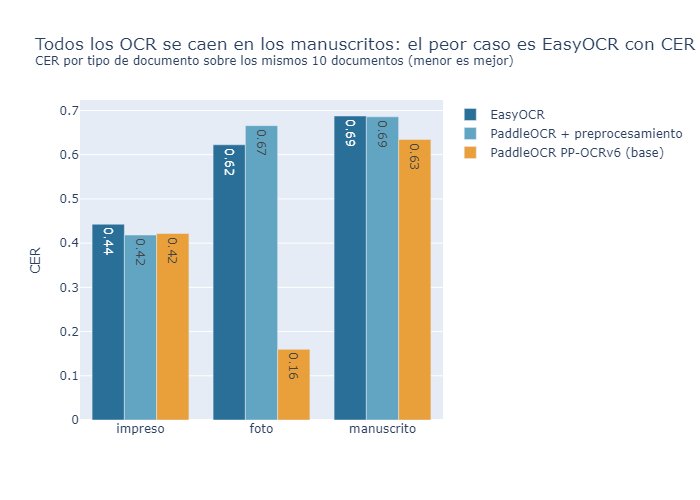

In [7]:
g = ev_ocr.assign(modelo=ev_ocr["modelo"].map(MODELOS_OCR)).groupby(["tipo", "modelo"]).apply(cer_modelo).rename("CER").reset_index()
peor = g.loc[g["CER"].idxmax()]
fig = px.bar(g, x="tipo", y="CER", color="modelo", barmode="group", text_auto=".2f",
             category_orders={"tipo": ["impreso", "foto", "manuscrito"]}, color_discrete_sequence=["#2a6f97", "#61a5c2", "#e9a03b"],
             title=(f"Todos los OCR se caen en los manuscritos: el peor caso es {peor['modelo']} con CER {peor['CER']:.2f}"
                    "<br><sup>CER por tipo de documento sobre los mismos 10 documentos (menor es mejor)</sup>"))
fig.update_layout(xaxis_title="", yaxis_title="CER", legend_title="")
fig.show()

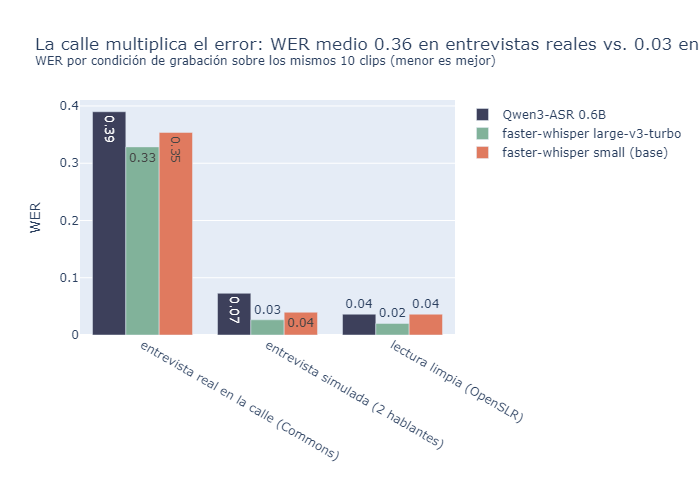

In [8]:
g = ev_asr.assign(modelo=ev_asr["modelo"].map(MODELOS_ASR)).groupby(["condicion", "modelo"]).apply(wer_modelo).rename("WER").reset_index()
lim = g[g["condicion"].str.startswith("lectura")]["WER"].mean()
calle = g[g["condicion"].str.startswith("entrevista real")]["WER"].mean()
fig = px.bar(g, x="condicion", y="WER", color="modelo", barmode="group", text_auto=".2f",
             color_discrete_sequence=["#3d405b", "#81b29a", "#e07a5f"],
             title=(f"La calle multiplica el error: WER medio {calle:.2f} en entrevistas reales vs. {lim:.2f} en lectura limpia"
                    "<br><sup>WER por condición de grabación sobre los mismos 10 clips (menor es mejor)</sup>"))
fig.update_layout(xaxis_title="", yaxis_title="WER", legend_title="")
fig.show()

### Latencia y costo

In [9]:
lat = pd.concat([
    ev_ocr.groupby("modelo")["segundos"].mean().rename("seg_por_unidad").to_frame().assign(unidad="s por documento"),
    ev_asr.groupby("modelo").apply(lambda d: d["segundos"].sum() / d["duracion_seg"].sum()).rename("seg_por_unidad").to_frame().assign(unidad="RTF (s cómputo / s audio)"),
])
lat["tamaño aprox."] = lat.index.map({"paddle_base": "~134 MB (det 60 MB + rec 74 MB)", "paddle_prepro": "~175 MB (+ orientación de página, UVDoc y orientación de línea)",
                                       "easyocr": "~94 MB (CRAFT + CRNN latino)", "fw-small": "244 M parámetros (~0,5 GB int8)",
                                       "fw-turbo": "809 M parámetros (~1,6 GB)", "qwen3-asr-0.6b": "600 M parámetros (~2,4 GB float32)"})
lat.round(3)

,seg_por_unidad,unidad,tamaño aprox.
modelo,,,
easyocr,34.381,s por documento,~94 MB (CRAFT + CRNN latino)
paddle_base,45.026,s por documento,~134 MB (det 60 MB + rec 74 MB)
paddle_prepro,52.223,s por documento,"~175 MB (+ orientación de página, UVDoc y orientación de línea)"
fw-small,0.143,RTF (s cómputo / s audio),"244 M parámetros (~0,5 GB int8)"
fw-turbo,0.202,RTF (s cómputo / s audio),"809 M parámetros (~1,6 GB)"
qwen3-asr-0.6b,0.574,RTF (s cómputo / s audio),"600 M parámetros (~2,4 GB float32)"


## 5. Casos difíciles

In [10]:
def errores(df, refs):
    m = jiwer.process_words([H.normalizar(refs[i]) for i in df["id"]], [H.normalizar(h) or "∅" for h in df["hipotesis"]])
    n = m.hits + m.substitutions + m.deletions
    return pd.Series({"sustituciones": m.substitutions / n, "borradas": m.deletions / n, "insertadas": m.insertions / n})


refs_c = dict(zip(muestra_clip["id"], muestra_clip["texto_referencia"]))
desglose = ev_asr.groupby(["condicion", "modelo"]).apply(lambda d: errores(d, refs_c)).round(3)
desglose

sustituciones  borradas  \
condicion                             modelo                                    
entrevista real en la calle (Commons) fw-small                0.227     0.101   
                                      fw-turbo                0.184     0.126   
                                      qwen3-asr-0.6b          0.267     0.083   
entrevista simulada (2 hablantes)     fw-small                0.040     0.000   
                                      fw-turbo                0.026     0.000   
                                      qwen3-asr-0.6b          0.066     0.007   
lectura limpia (OpenSLR)              fw-small                0.035     0.001   
                                      fw-turbo                0.019     0.001   
                                      qwen3-asr-0.6b          0.035     0.001   

                                                      insertadas  
condicion                             modelo                      
entrevista real en la calle (Commons) fw-small             0.025  
                                      fw-turbo             0.018  
                                      qwen3-asr-0.6b       0.040  
entrevista simulada (2 hablantes)     fw-small             0.000  
                                      fw-turbo             0.000  
                                      qwen3-asr-0.6b       0.000  
lectura limpia (OpenSLR)              fw-small             0.000  
                                      fw-turbo             0.000  
                                      qwen3-asr-0.6b       0.000

**¿Error de lectura o de orden?** El CER castiga igual un carácter mal leído que un texto bien leído pero en otro orden. Como diagnóstico (no reemplaza al CER) se calcula la **recuperación de palabras sin importar el orden**: qué fracción de las palabras de la referencia aparece en la salida del OCR.

In [11]:
from collections import Counter


def recuperacion_palabras(ref, hip):
    r, h = Counter(H.normalizar_doc(ref).split()), Counter(H.normalizar_doc(hip).split())
    return sum((r & h).values()) / max(1, sum(r.values()))


refs_d = dict(zip(muestra_doc["id"], muestra_doc["texto_referencia"]))
ev_ocr["recuperacion_palabras"] = [recuperacion_palabras(refs_d[i], h) for i, h in zip(ev_ocr["id"], ev_ocr["hipotesis"])]
diag = ev_ocr.pivot(index=["id", "tipo"], columns="modelo", values=["cer", "recuperacion_palabras"]).round(2)
d8 = ev_ocr[(ev_ocr["id"] == "doc_008") & (ev_ocr["modelo"] == "paddle_base")].iloc[0]
print(f"doc_008 (decreto a dos columnas) con PaddleOCR base: CER {d8.cer:.2f} pero recupera el {d8.recuperacion_palabras:.0%} de las palabras: "
      "el OCR lee bien los caracteres y mezcla las dos columnas renglón por renglón.")
diag

doc_008 (decreto a dos columnas) con PaddleOCR base: CER 0.70 pero recupera el 92% de las palabras: el OCR lee bien los caracteres y mezcla las dos columnas renglón por renglón.


cer                           recuperacion_palabras  \
modelo             easyocr paddle_base paddle_prepro               easyocr   
id      tipo                                                                 
doc_001 impreso       0.06        0.01          0.01                  0.76   
doc_003 impreso       0.07        0.00          0.01                  0.73   
doc_006 impreso       0.04        0.06          0.02                  0.85   
doc_008 impreso       0.71        0.70          0.70                  0.73   
doc_009 foto          0.56        0.44          0.91                  0.19   
doc_010 foto          0.69        0.14          0.65                  0.49   
doc_011 foto          0.50        0.14          0.64                  0.12   
doc_020 manuscrito    0.67        0.63          0.64                  0.00   
doc_021 manuscrito    0.77        1.77          1.00                  0.14   
doc_022 manuscrito    0.68        0.54          0.67                  0.03   

                                              
modelo             paddle_base paddle_prepro  
id      tipo                                  
doc_001 impreso           0.95          0.96  
doc_003 impreso           0.97          0.97  
doc_006 impreso           0.88          0.90  
doc_008 impreso           0.92          0.92  
doc_009 foto              0.31          0.00  
doc_010 foto              0.80          0.27  
doc_011 foto              0.38          0.29  
doc_020 manuscrito        0.14          0.00  
doc_021 manuscrito        0.43          0.29  
doc_022 manuscrito        0.05          0.04

In [12]:
# Ejemplos: un manuscrito, la placa con brillo y el clip con ruido de estadio
for i in ["doc_021", "doc_010"]:
    print(f"── {i} ({muestra_doc.set_index('id').loc[i, 'descripcion']})")
    print("REFERENCIA :", muestra_doc.set_index("id").loc[i, "texto_referencia"][:300])
    for clave in MODELOS_OCR:
        f = ev_ocr[(ev_ocr["id"] == i) & (ev_ocr["modelo"] == clave)].iloc[0]
        print(f"{clave:13s}: CER {f.cer:.2f} | {f.hipotesis[:300]!r}")
    print()
i = "clip_008"
print(f"── {i} (medio tiempo del Perú-Australia, ruido de estadio)")
print("REFERENCIA :", refs_c[i][:400])
for clave in MODELOS_ASR:
    f = ev_asr[(ev_asr["id"] == i) & (ev_asr["modelo"] == clave)].iloc[0]
    print(f"{clave:14s}: WER {f.wer:.2f} | {f.hipotesis[:400]}")

── doc_021 (Guaman Poma (1615), la villa de Cañete)
REFERENCIA : 1037 1045 LA VILLA DE CAÑETE CIVDAD
paddle_base  : CER 1.77 | '1045-\n1037\nCIVDAD\nLAVILLADECANETE\nR\n财\n雲\n5\n目\n0000\n鼎啦\n00\nAnnon\nA0\n\nPannd\n\n房A\nui lla\nesta'
paddle_prepro: CER 1.00 | '1037\nCIVDAD\nLAVILLADECANETE\nS\n聘\n目\n0000\n哑\n00\n\nui lla\nesta'
easyocr      : CER 0.77 | 'ous <\nh032\nCIVDAD\n[AVäLLADECAVFTF\n98 i\nestn'

── doc_010 (Placa metálica del Edificio Fénix, Lima (brillo fuerte))
REFERENCIA : EDIFICIO FÉNIX. El Edificio Fénix fue construido en 1934 por la firma Fred T. Ley Cía. Ltd. por encargo de la Compañía de Seguros La Fénix Peruana para albergar su sede social. El encargo consistió en añadir dos pisos y una azotea de departamentos a una finca existente de un solo piso donde funciona
paddle_base  : CER 0.14 | 'EDIFICIO FENIX\nEL EDIFICIO FENIX FVE CONSTRVIDO EN 1934 POR LA FIRMA FRED T. LEY\nSY VNA AZOTEADE\nCIA. LTD. POR ENCARCO DE LA COMPAÑIA DE SEGVROS LA FENIX PERVANA\nPARA ALBERGAR S

**Diarización.** En la Parte 1 la diarización se midió contra la verdad conocida de la entrevista simulada (ver `01_extraccion.ipynb`, sección 4); aquí se resume cuántos hablantes encontró en cada tipo de audio del corpus completo.

In [13]:
transcripciones.groupby("origen")["n_hablantes"].value_counts().unstack(fill_value=0)

n_hablantes,1,2,3
origen,,,
Commons (entrevista real),1,6,1
OpenSLR 73 (lectura),13,2,0


## 6. Extracción estructurada con LLM (Ollama, local)

Se usa **`qwen2.5:3b` en Ollama** (local, sin enviar datos a internet) con `format="json"`, `temperature=0` y un prompt por modalidad (`herramientas.PROMPT_DOCUMENTO` y `PROMPT_AUDIO`). El LLM recibe los **textos ya seudonimizados** de la Parte 1 (OCR de PaddleOCR y ASR de large-v3-turbo). Campos:
* todos: `modalidad`, `tema`, `resumen`;
* documentos: `tipo_documental`, `emisor`, `fecha`, `monto`, `lugar` (solo si aparecen);
* audios: `tipo_audio`, `numero_hablantes` (según las marcas `[HABLANTE_n]`), `citas_clave` (copiadas textualmente), `lugar`.

El prompt exige `null` para lo que no aparece y prohíbe completar con conocimiento externo.

In [14]:
print(H.PROMPT_DOCUMENTO[:900])

Extrae información estructurada de este documento peruano leído con OCR.
Devuelve un JSON con exactamente estas claves:
- "modalidad": "documento"
- "tema": tema principal en 2 a 6 palabras
- "resumen": 1 o 2 oraciones sobre lo que dice el documento
- "tipo_documental": "literario", "historico", "legal", "placa conmemorativa", "cronica" u "otro"
- "emisor": persona o institución que emite, dedica o firma el documento (null si no aparece)
- "fecha": fecha o año que aparezca escrito en el texto, tal cual (null si no aparece)
- "monto": cantidad de dinero que aparezca en el texto (null si no aparece)
- "lugar": lugar principal mencionado (null si no aparece)
Reglas:
- Responde SOLO con un objeto JSON válido, sin texto adicional.
- Usa null cuando el dato no aparece explícitamente en el texto. No inventes ni completes con conocimiento externo.
- El texto viene de un OCR y puede tener errores


In [15]:
registros = [(r.id, "documento", r.texto_ocr) for r in documentos.itertuples()] + \
            [(r.id, "audio", r.texto_asr) for r in transcripciones.itertuples()]
filas = []
for i, modalidad, texto in registros:
    e = H.en_cache(f"llm_{i}", H.extraer_llm, texto, modalidad)
    filas.append({"id": i, "modalidad": modalidad, "campos_json": json.dumps(e["campos"], ensure_ascii=False),
                  "modelo_llm": f"Ollama {H.MODELO_LLM} (format=json, temperature=0)", "fecha": "2026-10-25",
                  "segundos": e["segundos"], "json_valido": e["json_valido"]})
extraccion = pd.DataFrame(filas)
extraccion.to_csv(BASE / "datos" / "extraccion_llm.csv", index=False)
campos = pd.json_normalize(extraccion["campos_json"].map(json.loads))
print(f"{len(extraccion)} extracciones ({extraccion['json_valido'].mean():.0%} JSON válido, {extraccion['segundos'].mean():.1f} s cada una)")
print("Campos con null (dato ausente) por modalidad:")
print(campos.groupby("modalidad").apply(lambda d: d.isna().mean()).round(2).T.dropna(how="all").to_string())
extraccion.head(5)

48 extracciones (100% JSON válido, 11.5 s cada una)
Campos con null (dato ausente) por modalidad:
modalidad         audio  documento
tema               0.00       0.00
resumen            0.00       0.04
tipo_documental    1.00       0.16
emisor             1.00       0.92
fecha              1.00       0.60
monto              1.00       1.00
lugar              0.87       0.64
tipo_audio         0.04       1.00
numero_hablantes   0.52       1.00
citas_clave        0.00       1.00


,id,modalidad,campos_json,modelo_llm,fecha,segundos,json_valido
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Escriuano y el diablo"", ""resumen"": ""El documento cuenta la historia de...","Ollama qwen2.5:3b (format=json, temperature=0)",2026-10-25,18.47,True
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""amor y tentación"", ""resumen"": ""El texto describe una historia de amor ...","Ollama qwen2.5:3b (format=json, temperature=0)",2026-10-25,12.77,True
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Historia del Perú"", ""resumen"": ""El texto describe la situación de dos ...","Ollama qwen2.5:3b (format=json, temperature=0)",2026-10-25,11.19,True
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Historia militar peruana"", ""resumen"": ""El documento relata la historia...","Ollama qwen2.5:3b (format=json, temperature=0)",2026-10-25,12.98,True
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Historia del Perú"", ""resumen"": ""El documento trata sobre la historia d...","Ollama qwen2.5:3b (format=json, temperature=0)",2026-10-25,6.83,True


**Chequeos automáticos (no reemplazan la auditoría):** las `citas_clave` deberían aparecer textualmente en la transcripción y `numero_hablantes` debería coincidir con las marcas `[HABLANTE_n]`.

In [16]:
aud = extraccion[extraccion["modalidad"] == "audio"].merge(transcripciones[["id", "texto_asr", "n_hablantes"]], on="id")
def citas_ok(r):
    citas = json.loads(r.campos_json).get("citas_clave") or []
    citas = [citas] if isinstance(citas, str) else [str(c) for c in citas]
    return np.mean([H.normalizar(c)[:60] in H.normalizar(r.texto_asr) for c in citas]) if citas else np.nan
aud["citas_textuales"] = aud.apply(citas_ok, axis=1)
aud["hablantes_llm"] = pd.to_numeric(aud["campos_json"].map(lambda s: json.loads(s).get("numero_hablantes")), errors="coerce")
aud["marcas"] = aud["texto_asr"].map(lambda t: len(set(re.findall(r"\[HABLANTE_\d+\]", t))) or np.nan)
print(f"Citas que aparecen textualmente: {aud['citas_textuales'].mean():.0%} | numero_hablantes coincide con las marcas: "
      f"{(aud['hablantes_llm'].fillna(0) == aud['marcas'].fillna(0)).mean():.0%}")

Citas que aparecen textualmente: 57% | numero_hablantes coincide con las marcas: 83%


### Auditoría humana de 20 extracciones

Muestra al azar (semilla 2026) de **10 documentos y 10 audios** del corpus procesado. La revisión la hice a mano en `datos/auditoria_llm.csv`, comparando cada JSON con el texto fuente.

**Criterios de corrección** (fijados antes de revisar):
* `tema_ok`: el tema corresponde al contenido principal del texto.
* `resumen_ok`: el resumen es fiel; cualquier hecho que no está en el texto (nombre, fecha, lugar inventado) lo invalida.
* `campos_ok`: cada campo específico es correcto **o** es `null` cuando el dato no está. Un valor inventado, o un dato presente que quedó en `null`, es error. Las citas deben estar en la transcripción y `numero_hablantes` debe coincidir con las marcas.
* `correcta = si` solo si los tres criterios se cumplen (extracción completamente correcta).

In [17]:
ruta_aud = BASE / "datos" / "auditoria_llm.csv"
rng = np.random.default_rng(2026)
ids_aud = list(rng.choice(documentos["id"], 10, replace=False)) + list(rng.choice(transcripciones["id"], 10, replace=False))
if not ruta_aud.exists():  # se crea la hoja vacía; las columnas de juicio se llenan a mano
    textos = {**dict(zip(documentos["id"], documentos["texto_ocr"])), **dict(zip(transcripciones["id"], transcripciones["texto_asr"]))}
    hoja = extraccion.set_index("id").loc[ids_aud, ["modalidad", "campos_json"]].reset_index()
    hoja.insert(2, "texto_fuente", hoja["id"].map(textos))
    for c in ["tema_ok", "resumen_ok", "campos_ok", "correcta", "error_observado"]:
        hoja[c] = ""
    hoja.to_csv(ruta_aud, index=False, encoding="utf-8-sig")
auditoria = pd.read_csv(ruta_aud, keep_default_na=False, encoding="utf-8-sig")
assert sorted(auditoria["id"]) == sorted(ids_aud), "La hoja de auditoría no corresponde a la muestra"
sin_juicio = (auditoria["correcta"].str.strip() == "").sum()
correctas = (auditoria["correcta"].str.strip().str.lower() == "si").sum()
if sin_juicio:  # criterio conservador: solo cuenta como correcta la que el auditor marcó "si"
    print(f"Atención: {sin_juicio} extracción(es) sin juicio en la hoja; se cuentan como NO confirmadas.")
print(f"Acuerdo LLM-humano: {correctas}/20 extracciones completamente correctas ({correctas / 20:.0%})")
print(auditoria.groupby("modalidad")["correcta"].apply(lambda s: (s.str.lower() == "si").sum()).to_string())
print("\nPor criterio:", {c: f"{(auditoria[c].str.lower() == 'si').mean():.0%}" for c in ["tema_ok", "resumen_ok", "campos_ok"]})

Atención: 1 extracción(es) sin juicio en la hoja; se cuentan como NO confirmadas.


Acuerdo LLM-humano: 17/20 extracciones completamente correctas (85%)
modalidad
audio        10
documento     7

Por criterio: {'tema_ok': '90%', 'resumen_ok': '95%', 'campos_ok': '90%'}


In [18]:
auditoria.loc[auditoria["correcta"].str.lower() != "si", ["id", "modalidad", "campos_json", "error_observado"]]

,id,modalidad,campos_json,error_observado
0,doc_001,documento,"{\n ""modalidad"": ""documento"",\n ""tema"": ""Escriuano y el diablo"",\n ""resumen"": ""El documento cuenta la hist...",no es el tema\n
1,doc_026,documento,"{\n ""modalidad"": ""documento"",\n ""tema"": ""Política"",\n ""resumen"": ""Se menciona a un candidato y un partido ...",resumen equivocado
8,doc_009,documento,"{\n ""modalidad"": ""documento"",\n ""tema"": ""Día de la Raza"",\n ""resumen"": ""El documento se refiere al Día de ...",


## 7. Comparativa final y decisión

In [19]:
cer_m = {k: cer_modelo(ev_ocr[ev_ocr["modelo"] == k]) for k in MODELOS_OCR}
wer_m = {k: wer_modelo(ev_asr[ev_asr["modelo"] == k]) for k in MODELOS_ASR}
seg_m = {k: ev_ocr.loc[ev_ocr["modelo"] == k, "segundos"].mean() for k in MODELOS_OCR}
rtf_m = {k: ev_asr.loc[ev_asr["modelo"] == k, "segundos"].sum() / ev_asr.loc[ev_asr["modelo"] == k, "duracion_seg"].sum() for k in MODELOS_ASR}
# Regla fijada antes de medir: menor error; a igualdad práctica (misma cifra a 2 decimales), el más rápido
elegido_ocr = min(cer_m, key=lambda k: (round(cer_m[k], 2), seg_m[k]))
elegido_asr = min(wer_m, key=lambda k: (round(wer_m[k], 2), rtf_m[k]))
cer_final = cer_modelo(ev_ocr[ev_ocr["modelo"] == elegido_ocr])
wer_final = wer_modelo(ev_asr[ev_asr["modelo"] == elegido_asr])
print(f"Resultados Test: WER: {wer_final:.2f} | CER: {cer_final:.2f} | Acuerdo LLM-Humano: {correctas}/20")
print(f"(OCR elegido: {MODELOS_OCR[elegido_ocr]} · ASR elegido: {MODELOS_ASR[elegido_asr]})")
comparativa.round(3)

Resultados Test: WER: 0.09 | CER: 0.40 | Acuerdo LLM-Humano: 17/20
(OCR elegido: PaddleOCR PP-OCRv6 (base) · ASR elegido: faster-whisper large-v3-turbo)


,modalidad,modelo,métrica,valor (muestra),CER impreso,CER foto,CER manuscrito,latencia,WER entrevista real en la calle,WER lectura limpia,WER entrevista simulada
0,documentos,PaddleOCR PP-OCRv6 (base),CER,0.399,0.422,0.160,0.634,45.0 s/doc,NaN,NaN,NaN
1,documentos,PaddleOCR + preprocesamiento,CER,0.465,0.418,0.666,0.686,52.2 s/doc,NaN,NaN,NaN
2,documentos,EasyOCR,CER,0.480,0.443,0.622,0.688,34.4 s/doc,NaN,NaN,NaN
3,audio,faster-whisper small (base),WER,0.112,NaN,NaN,NaN,RTF 0.14,0.354,0.036,0.040
4,audio,faster-whisper large-v3-turbo,WER,0.094,NaN,NaN,NaN,RTF 0.20,0.329,0.020,0.026
5,audio,Qwen3-ASR 0.6B,WER,0.125,NaN,NaN,NaN,RTF 0.57,0.390,0.036,0.073


In [20]:
print("DECISIÓN")
print(f"• Documentos → {MODELOS_OCR[elegido_ocr]}: CER {cer_m[elegido_ocr]:.3f} vs. " + ", ".join(f"{MODELOS_OCR[k]} {v:.3f}" for k, v in cer_m.items() if k != elegido_ocr)
      + "; latencia " + ", ".join(f"{MODELOS_OCR[k]} {v:.0f} s/doc" for k, v in seg_m.items()) + ". Todos son gratuitos, locales y corren sin GPU.")
print(f"• Audio → {MODELOS_ASR[elegido_asr]}: WER {wer_m[elegido_asr]:.3f} vs. " + ", ".join(f"{MODELOS_ASR[k]} {v:.3f}" for k, v in wer_m.items() if k != elegido_asr)
      + "; RTF " + ", ".join(f"{MODELOS_ASR[k]} {v:.2f}" for k, v in rtf_m.items()) + " (RTF < 1 = más rápido que el tiempo real en CPU).")
print()
print("REFLEXIÓN POR TIPO")
for t in ["impreso", "foto", "manuscrito"]:
    print(f"• {t:10s}: CER " + " | ".join(f"{MODELOS_OCR[k]} {cer_modelo(ev_ocr[(ev_ocr['modelo'] == k) & (ev_ocr['tipo'] == t)]):.2f}" for k in MODELOS_OCR))
for c in muestra_clip["condicion"].unique():
    print(f"• {c}: WER " + " | ".join(f"{MODELOS_ASR[k]} {wer_modelo(ev_asr[(ev_asr['modelo'] == k) & (ev_asr['condicion'] == c)]):.2f}" for k in MODELOS_ASR))

DECISIÓN
• Documentos → PaddleOCR PP-OCRv6 (base): CER 0.399 vs. PaddleOCR + preprocesamiento 0.465, EasyOCR 0.480; latencia PaddleOCR PP-OCRv6 (base) 45 s/doc, PaddleOCR + preprocesamiento 52 s/doc, EasyOCR 34 s/doc. Todos son gratuitos, locales y corren sin GPU.
• Audio → faster-whisper large-v3-turbo: WER 0.094 vs. faster-whisper small (base) 0.112, Qwen3-ASR 0.6B 0.125; RTF faster-whisper small (base) 0.14, faster-whisper large-v3-turbo 0.20, Qwen3-ASR 0.6B 0.57 (RTF < 1 = más rápido que el tiempo real en CPU).

REFLEXIÓN POR TIPO


• impreso   : CER PaddleOCR PP-OCRv6 (base) 0.42 | PaddleOCR + preprocesamiento 0.42 | EasyOCR 0.44
• foto      : CER PaddleOCR PP-OCRv6 (base) 0.16 | PaddleOCR + preprocesamiento 0.67 | EasyOCR 0.62
• manuscrito: CER PaddleOCR PP-OCRv6 (base) 0.63 | PaddleOCR + preprocesamiento 0.69 | EasyOCR 0.69
• entrevista real en la calle (Commons): WER faster-whisper small (base) 0.35 | faster-whisper large-v3-turbo 0.33 | Qwen3-ASR 0.6B 0.39


• lectura limpia (OpenSLR): WER faster-whisper small (base) 0.04 | faster-whisper large-v3-turbo 0.02 | Qwen3-ASR 0.6B 0.04
• entrevista simulada (2 hablantes): WER faster-whisper small (base) 0.04 | faster-whisper large-v3-turbo 0.03 | Qwen3-ASR 0.6B 0.07


**Lectura de los resultados (casos difíciles).**
* **Manuscritos:** los OCR están entrenados con letra impresa; en Guaman Poma (1615) aciertan sobre todo los títulos en mayúsculas y, sobre los dibujos, el reconocedor multilingüe de PP-OCRv6 "inventa" caracteres chinos (inserciones: CER > 1 en `doc_021`). Haría falta un modelo de escritura a mano (HTR) entrenado en paleografía hispana.
* **Fotos de placas:** brillo del bronce, relieve, V por U y letras pegadas. La corrección de deformación (UVDoc) de PaddleOCR **empeora** las placas, porque "desdobla" una superficie que ya es plana; ayuda en la página de Garcilaso, que sí tiene curvatura.
* **Impresos:** casi perfectos en Palma y Garcilaso; el decreto de 1969 a **dos columnas** tiene CER alto en los 3 modelos por **orden de lectura**, no por caracteres (su recuperación de palabras es alta). En producción haría falta análisis de diseño antes del OCR.
* **Audio:** la lectura limpia de OpenSLR tiene WER bajo; las entrevistas reales en la calle (ruido, habla espontánea, voces superpuestas) multiplican el error. El VAD evita transcribir silencios, pero no el ruido de fondo.
* **Diarización:** 100 % correcta en la entrevista simulada y 3 voces separadas en El Agustino, pero partió en 2 a un lector de OpenSLR (`clip_022`): un umbral fijo no sirve igual para todas las voces.

In [21]:
# Archivos para el dashboard: métricas por documento/clip y resumen
ev_ocr.to_csv(BASE / "datos" / "evaluacion_ocr.csv", index=False)
ev_asr.to_csv(BASE / "datos" / "evaluacion_asr.csv", index=False)
metricas = {
    "fecha": str(date(2026, 10, 25)),
    "muestra": {"documentos": DOCS_EVAL, "clips": CLIPS_EVAL},
    "ocr": {k: {"nombre": v, "cer": cer_modelo(ev_ocr[ev_ocr["modelo"] == k]),
                "cer_por_tipo": {t: cer_modelo(ev_ocr[(ev_ocr["modelo"] == k) & (ev_ocr["tipo"] == t)]) for t in ["impreso", "foto", "manuscrito"]},
                "seg_por_doc": float(ev_ocr.loc[ev_ocr["modelo"] == k, "segundos"].mean())} for k, v in MODELOS_OCR.items()},
    "asr": {k: {"nombre": v, "wer": wer_modelo(ev_asr[ev_asr["modelo"] == k]),
                "wer_por_condicion": {c: wer_modelo(ev_asr[(ev_asr["modelo"] == k) & (ev_asr["condicion"] == c)]) for c in muestra_clip["condicion"].unique()},
                "rtf": float(ev_asr.loc[ev_asr["modelo"] == k, "segundos"].sum() / ev_asr.loc[ev_asr["modelo"] == k, "duracion_seg"].sum())}
            for k, v in MODELOS_ASR.items()},
    "elegidos": {"ocr": elegido_ocr, "asr": elegido_asr},
    "auditoria": {"correctas": int(correctas), "total": 20},
}
(BASE / "datos" / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=1), encoding="utf-8")
print("Guardados: evaluacion_ocr.csv, evaluacion_asr.csv, metricas.json")

Guardados: evaluacion_ocr.csv, evaluacion_asr.csv, metricas.json
